# CardioRitmo · Tamizaje de latidos anormales (DEV)

**Cliente:** CardioRitmo, fabricante de monitores Holter.
**Objetivo:** que el monitor señale los latidos anormales, de modo que el cardiólogo
revise únicamente esos.

**Especificaciones del cliente (en la prueba, con umbral de 0.5):**
- sensibilidad ≥ 95 % (de cada 100 latidos anormales, señalar al menos 95);
- especificidad ≥ 95 % (de cada 100 latidos normales, señalar como máximo 5);
- tamaño compatible con el monitor: **≤ 20,000 parámetros**.

Todas las decisiones se toman con el conjunto de **validación**; la prueba del cliente
se utiliza **una sola vez, al final**.

In [1]:
import os
import warnings

# TF en Windows no ve la GPU; Keras 3 sobre PyTorch sí
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import torch

# aviso interno e inofensivo de PyTorch al usar la GRU en GPU
warnings.filterwarnings("ignore", message="RNN module weights")

# resultados reproducibles en GPU (misma salida en cada ejecución)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)
print(
    "Keras",
    keras.__version__,
    "| backend:",
    keras.backend.backend(),
    "| GPU:",
    torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no",
)

Keras 3.15.1 | backend: torch | GPU: NVIDIA GeForce GTX 1660 SUPER


## 1. Datos

ECG5000 (archivo UCR): latidos de 140 puntos provenientes de **un solo paciente** con
insuficiencia cardiaca (base BIDMC, PhysioNet). La carga y la división se realizan
**exactamente** como se especifican en el enunciado.

In [2]:
# fmt: off
import pandas as pd
from sklearn.model_selection import train_test_split

ecg = pd.read_csv("https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = ecg.iloc[:, :-1].to_numpy("float32")   # 140 puntos por latido
y = 1 - ecg.iloc[:, -1].to_numpy("int64")  # el archivo trae 1 = normal; aquí 1 = ANORMAL

# Prueba del cliente: 20 % estratificado. No la toquen hasta el final.
X_resto, X_prueba, y_resto, y_prueba = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# Con X_resto y y_resto armen su entrenamiento y su validación como quieran.

## 2. Exploración

Tamaño y balance de clases. A partir de este punto la exploración utiliza
**únicamente `X_resto`**, a fin de no inspeccionar la prueba.

In [3]:
print("Latidos totales:", X.shape[0], "| puntos por latido:", X.shape[1])
print("Valores faltantes:", int(np.isnan(X).sum()))
balance = pd.DataFrame(
    {
        "total": pd.Series(y).value_counts(),
        "resto": pd.Series(y_resto).value_counts(),
        "prueba": pd.Series(y_prueba).value_counts(),
    }
).rename(index={0: "normal (0)", 1: "anormal (1)"})
balance.loc["% anormal"] = (balance.loc["anormal (1)"] / balance.sum() * 100).round(1)
balance

Latidos totales: 4998 | puntos por latido: 140
Valores faltantes: 0


,total,resto,prueba
normal (0),2919.0,2335.0,584.0
anormal (1),2079.0,1663.0,416.0
% anormal,41.6,41.6,41.6


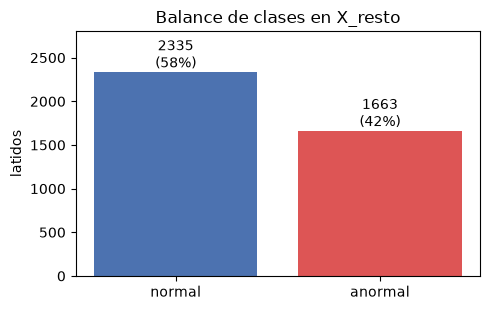

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
conteo = pd.Series(y_resto).value_counts().sort_index()
ax.bar(["normal", "anormal"], conteo.values, color=["#4C72B0", "#DD5555"])
for i, v in enumerate(conteo.values):
    ax.text(i, v, f"{v}\n({v / conteo.sum():.0%})", ha="center", va="bottom")
ax.set_title("Balance de clases en X_resto")
ax.set_ylabel("latidos")
ax.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout()
plt.show()

**Ejemplos:** cinco latidos de cada clase, seleccionados al azar.

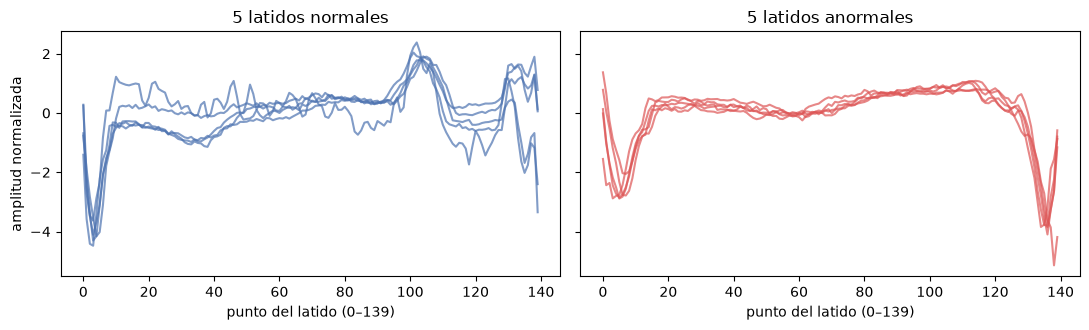

In [5]:
rng = np.random.default_rng(SEMILLA)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, clase, nombre, color in zip(
    axes, [0, 1], ["normales", "anormales"], ["#4C72B0", "#DD5555"]
):
    for i in rng.choice(np.where(y_resto == clase)[0], 5, replace=False):
        ax.plot(X_resto[i], color=color, alpha=0.7)
    ax.set_title(f"5 latidos {nombre}")
    ax.set_xlabel("punto del latido (0–139)")
axes[0].set_ylabel("amplitud normalizada")
plt.tight_layout()
plt.show()

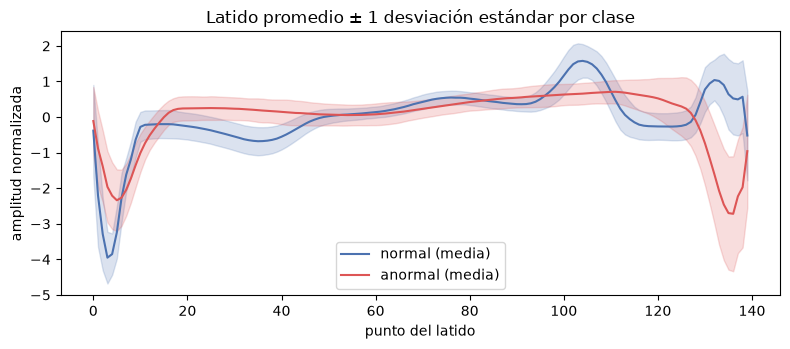

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for clase, nombre, color in [(0, "normal", "#4C72B0"), (1, "anormal", "#DD5555")]:
    m, s = X_resto[y_resto == clase].mean(0), X_resto[y_resto == clase].std(0)
    ax.plot(m, color=color, label=f"{nombre} (media)")
    ax.fill_between(range(140), m - s, m + s, color=color, alpha=0.2)
ax.set_title("Latido promedio ± 1 desviación estándar por clase")
ax.set_xlabel("punto del latido")
ax.set_ylabel("amplitud normalizada")
ax.legend()
plt.tight_layout()
plt.show()

**Observaciones:**
- El conjunto contiene 4,998 latidos de 140 puntos, sin valores faltantes. El 41.6 %
  son anormales, por lo que las clases están razonablemente balanceadas.
- Las dos clases se distinguen con claridad en su forma promedio, sobre todo al final
  del latido, lo que sugiere que un modelo pequeño puede ser suficiente.
- El latido anormal típico carece del pico cercano al punto 105 y desciende al final
  (puntos 125–139). En esa zona su banda de ±1 desviación estándar es más amplia, por
  lo que se espera que los anormales de forma atípica concentren los errores.
- **Limitación principal:** todos los datos provienen de un solo paciente; lo que el
  modelo aprenda describe *sus* latidos y no necesariamente los de otras personas.

## 3. Preparación

**División.** La prueba ya se encuentra apartada. De `X_resto` se extrae un 20 %
estratificado para **validación**, con el cual se eligen la arquitectura, el número de
épocas y el modelo final. La prueba no se vuelve a utilizar hasta la sección de
resultados.

In [7]:
X_ent, X_val, y_ent, y_val = train_test_split(
    X_resto, y_resto, test_size=0.2, stratify=y_resto, random_state=SEMILLA
)
pd.DataFrame(
    {
        "latidos": [len(y_ent), len(y_val), len(y_prueba)],
        "% anormal": [y_ent.mean() * 100, y_val.mean() * 100, y_prueba.mean() * 100],
    },
    index=["entrenamiento", "validación", "prueba (cerrada)"],
).round(1)

,latidos,% anormal
entrenamiento,3198,41.6
validación,800,41.6
prueba (cerrada),1000,41.6


**Transformación.** Cada latido ya viene normalizado (z-score por latido: media 0 y
desviación estándar 1). Esta normalización emplea solo los 140 puntos del propio
latido, por lo que no combina información entre latidos ni introduce fuga desde la
prueba. Se verifica a continuación y no se agrega otro escalado, ya que un escalador
ajustado sobre datos de validación o prueba constituiría una fuente de fuga.

Para las redes convolucionales y recurrentes, cada latido se representa como una
secuencia de 140 pasos con 1 canal, con forma `(latidos, 140, 1)`.

In [8]:
medias, desv = X_ent.mean(axis=1), X_ent.std(axis=1)
print(f"media por latido: [{medias.min():.4f}, {medias.max():.4f}]")
print(f"desv. por latido: [{desv.min():.4f}, {desv.max():.4f}]")

X_ent_seq, X_val_seq = X_ent[..., None], X_val[..., None]
print("forma para Conv1D/RNN:", X_ent_seq.shape, X_val_seq.shape)

media por latido: [-0.0000, 0.0000]
desv. por latido: [0.9964, 0.9964]
forma para Conv1D/RNN: (3198, 140, 1) (800, 140, 1)


## 4. Métricas del cliente

Las especificaciones se expresan en **sensibilidad** (proporción de latidos anormales
que el modelo señala) y **especificidad** (proporción de latidos normales que el
modelo no señala), con umbral de 0.5. Se reporta además el **AUC**, que no depende
del umbral. Una única función evalúa todos los modelos con el mismo criterio.

In [9]:
from sklearn.metrics import confusion_matrix, roc_auc_score

UMBRAL = 0.5
META = 0.95
MAX_PARAMETROS = 20_000


def metricas(y_real, prob, umbral=UMBRAL):
    """Sensibilidad, especificidad y AUC de probabilidades de 'anormal'."""
    vn, fp, fn, vp = confusion_matrix(y_real, prob >= umbral, labels=[0, 1]).ravel()
    return {
        "sensibilidad": vp / (vp + fn),
        "especificidad": vn / (vn + fp),
        "auc": roc_auc_score(y_real, prob),
    }


def cumple(m, parametros):
    return bool(
        m["sensibilidad"] >= META
        and m["especificidad"] >= META
        and parametros <= MAX_PARAMETROS
    )


# autoverificación: un clasificador perfecto da 1, 1, 1
assert metricas(np.array([0, 1, 1]), np.array([0.1, 0.9, 0.6])) == {
    "sensibilidad": 1.0,
    "especificidad": 1.0,
    "auc": 1.0,
}

## 5. Línea base trivial

La línea base predice siempre la clase más frecuente (**normal**) y asigna como
probabilidad la proporción de anormales observada en entrenamiento. No tiene
parámetros entrenables y establece el desempeño mínimo que cualquier modelo debe
superar.

In [10]:
from sklearn.dummy import DummyClassifier

base = DummyClassifier(strategy="prior").fit(X_ent, y_ent)
prob_base_val = base.predict_proba(X_val)[:, 1]

validacion = {}  # aquí se acumulan las métricas en validación de cada modelo
validacion["Línea base (clase mayoritaria)"] = metricas(y_val, prob_base_val) | {
    "parametros": 0
}
pd.DataFrame(validacion).T

,sensibilidad,especificidad,auc,parametros
Línea base (clase mayoritaria),0.0,1.0,0.5,0.0


La línea base **no señala ningún latido** (sensibilidad de 0 %). Su especificidad es
perfecta, pero carece de utilidad para el cliente, y su AUC de 0.5 equivale a una
asignación aleatoria.

## 6. Modelos

Todos los modelos se entrenan con el mismo procedimiento, para que la comparación sea
justa:
- pérdida de entropía cruzada binaria y optimizador Adam;
- hasta 150 épocas con **parada temprana** sobre la pérdida de validación (paciencia
  de 15), recuperando los mejores pesos;
- umbral fijo en 0.5, como lo establece el cliente; no se ajusta.

Dado que la validación determina el momento de parada, sus métricas son ligeramente
optimistas; la evaluación definitiva corresponde a la prueba.

In [11]:
from keras import layers


def entrenar(modelo, X_e, X_v, epocas=150, lote=64):
    """Entrena con parada temprana sobre validación y registra sus métricas."""
    keras.utils.set_random_seed(SEMILLA)
    modelo.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc")],
    )
    historia = modelo.fit(
        X_e,
        y_ent,
        validation_data=(X_v, y_val),
        epochs=epocas,
        batch_size=lote,
        callbacks=[
            keras.callbacks.EarlyStopping(
                patience=15, restore_best_weights=True, monitor="val_loss"
            )
        ],
        verbose=0,
    )
    parametros = modelo.count_params()
    prob_val = modelo.predict(X_v, verbose=0).ravel()
    validacion[modelo.name] = metricas(y_val, prob_val) | {"parametros": parametros}
    print(
        f"{modelo.name}: {parametros:,} parámetros | "
        f"{len(historia.history['loss'])} épocas | cumple el límite de tamaño: "
        f"{parametros <= MAX_PARAMETROS}"
    )
    return historia


def curvas(historia, titulo):
    _, axes = plt.subplots(1, 2, figsize=(10, 3.2))
    for ax, clave, nombre in zip(axes, ["loss", "auc"], ["pérdida", "AUC"]):
        ax.plot(historia.history[clave], label="entrenamiento")
        ax.plot(historia.history[f"val_{clave}"], label="validación")
        ax.set_title(f"{titulo}: {nombre}")
        ax.set_xlabel("época")
        ax.legend()
    plt.tight_layout()
    plt.show()

### 6.1 MLP (red densa)

Es el modelo más sencillo: trata los 140 puntos como 140 variables independientes, sin
considerar que forman una secuencia. Consta de dos capas ocultas pequeñas con
*dropout* para reducir el sobreajuste a los 3,198 latidos de entrenamiento.

In [12]:
mlp = keras.Sequential(
    [
        keras.Input(shape=(140,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="MLP",
)
mlp.summary()

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,137 (43.50 KB)

 Trainable params: 11,137 (43.50 KB)

 Non-trainable params: 0 (0.00 B)

MLP: 11,137 parámetros | 21 épocas | cumple el límite de tamaño: True


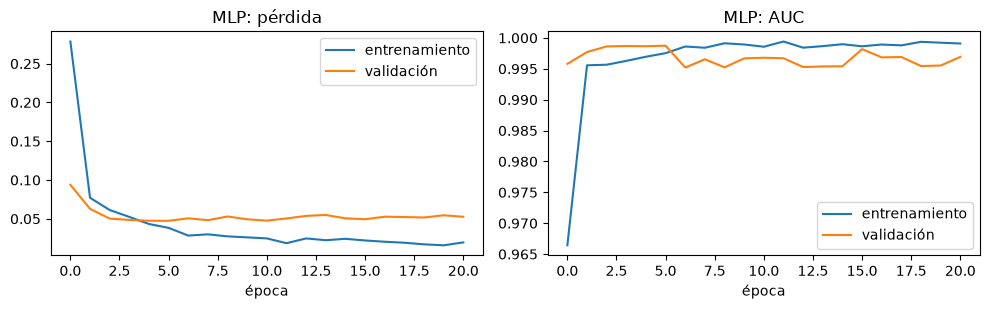

,sensibilidad,especificidad,auc,parametros
Línea base (clase mayoritaria),0.000000,1.000000,0.500000,0.0
MLP,0.972973,0.991435,0.998759,11137.0


In [13]:
historia_mlp = entrenar(mlp, X_ent, X_val)
curvas(historia_mlp, "MLP")
pd.DataFrame(validacion).T

**Resultados del MLP.** Con 11,137 parámetros (55 % del límite), el modelo supera
ambas metas en validación: sensibilidad de 97.3 % y especificidad de 99.1 %, con AUC
de 0.999. La pérdida de validación se estabiliza alrededor de la época 6 y la parada
temprana detiene el entrenamiento en la época 21, por lo que no se requiere un modelo
más grande. No obstante, se evalúan también modelos que **sí consideran la estructura
secuencial** (Conv1D y GRU), ya que un MLP es sensible a desplazamientos temporales
del latido, frecuentes en un registro Holter real.

### 6.2 Conv1D (red convolucional)

Las convoluciones recorren el latido con filtros pequeños que detectan patrones
locales (picos, pendientes) sin importar su posición exacta. Se apilan tres bloques
convolucionales con *max pooling*, que reducen la secuencia de 140 a 17 pasos, y un
promedio global antes de la capa de salida. Este diseño reutiliza los mismos filtros
a lo largo de todo el latido, por lo que requiere pocos parámetros.

In [14]:
conv = keras.Sequential(
    [
        keras.Input(shape=(140, 1)),
        layers.Conv1D(16, 7, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="Conv1D",
)
conv.summary()

Model: "Conv1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 140, 16)        │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 70, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 70, 32)         │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 35, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 35, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 17, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,369 (24.88 KB)

 Trainable params: 6,369 (24.88 KB)

 Non-trainable params: 0 (0.00 B)

Conv1D: 6,369 parámetros | 89 épocas | cumple el límite de tamaño: True


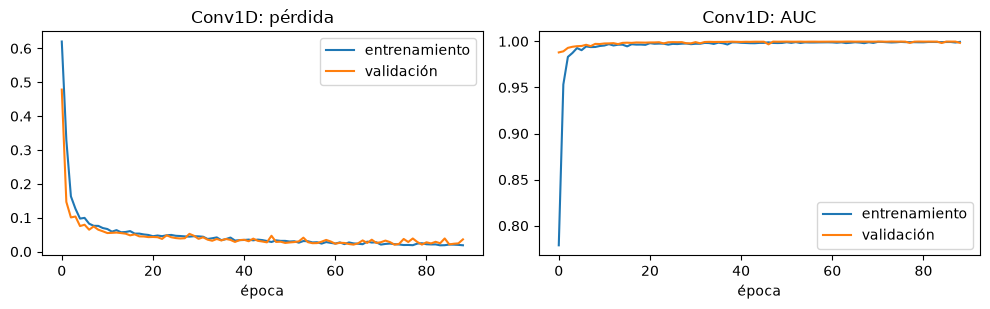

In [15]:
historia_conv = entrenar(conv, X_ent_seq, X_val_seq)
curvas(historia_conv, "Conv1D")

### 6.3 GRU (red recurrente)

La GRU lee el latido punto por punto y mantiene un estado interno que resume lo
observado hasta ese momento; la clasificación se basa en el estado final, tras leer
los 140 puntos. Se emplea una sola capa de 32 unidades, suficiente para el tamaño del
conjunto y muy por debajo del límite de parámetros.

In [16]:
gru = keras.Sequential(
    [
        keras.Input(shape=(140, 1)),
        layers.GRU(32),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="GRU",
)
gru.summary()

Model: "GRU"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 32)             │         3,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

GRU: 3,393 parámetros | 96 épocas | cumple el límite de tamaño: True


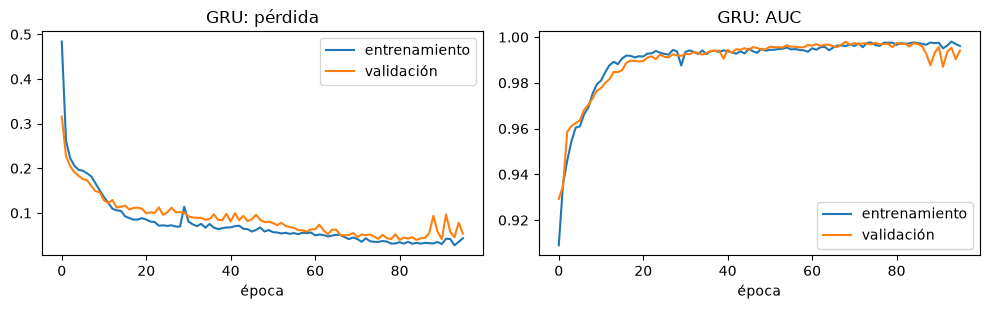

In [17]:
historia_gru = entrenar(gru, X_ent_seq, X_val_seq)
curvas(historia_gru, "GRU")

### 6.4 Comparación en validación

Tabla con los cuatro modelos evaluados sobre los 800 latidos de validación. La prueba
del cliente sigue sin utilizarse.

In [18]:
tabla_val = pd.DataFrame(validacion).T
tabla_val["parametros"] = tabla_val["parametros"].astype(int)
tabla_val["cumple en validación"] = [
    cumple(m, m["parametros"]) for m in validacion.values()
]
tabla_val.round(4)

,sensibilidad,especificidad,auc,parametros,cumple en validación
Línea base (clase mayoritaria),0.000,1.0000,0.5000,0,False
MLP,0.973,0.9914,0.9988,11137,True
Conv1D,0.997,0.9914,0.9998,6369,True
GRU,0.970,1.0000,0.9975,3393,True


**Análisis de la comparación.** Los tres modelos entrenados cumplen ambas metas en
validación y ocupan entre el 17 % y el 56 % del límite de parámetros. Sobre los 333
latidos anormales y 467 normales de validación:
- **Conv1D** (6,369 parámetros) omite 1 latido anormal y señala 4 normales; obtiene la
  mayor sensibilidad (99.7 %) y el mayor AUC (0.9998).
- **MLP** (11,137 parámetros) omite 9 anormales y señala 4 normales.
- **GRU** (3,393 parámetros) no señala ningún normal, pero omite 10 anormales; su
  sensibilidad de 97.0 % es la más cercana a la meta. Además, es la más lenta de
  entrenar (96 épocas, lectura secuencial de 140 pasos).

Para un tamizaje, omitir un latido anormal es más grave que enviar uno normal a revisión,
por lo que la sensibilidad es el criterio prioritario, siempre que se respete la
especificidad. Con base en la validación, la **Conv1D** es la candidata principal; la
selección final y su verificación en la prueba se presentan en la siguiente sección.